## Import packages and set outputs

In [1]:
%matplotlib inline

from pathlib import Path

import anndata as ad
import pandas as pd
import matplotlib.pyplot as plt
from gei_nj import comb_depth_ratio, filter_snvs, assign_state, zero_filling
from gei_nj import build_nj, view_tree_coords

plt.rcParams.update({"font.family": "sans-serif", "font.sans-serif": ["Arial", "DejaVu Sans"],
                     "pdf.fonttype": 42, "ps.fonttype": 42})

RAPIDNJ_BINARY = "rapidnj"

OUTPUT_DIR = Path("GEI-NJ_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Load depth and ratio matrices

In [2]:
depth = ad.read_h5ad("data/sc_depth.h5ad")
ratio = ad.read_h5ad("data/sc_ratio.h5ad")
adata = comb_depth_ratio(depth, ratio)

## Process SNVs with the default binary method

The defaults use binary states with `state_low=0.01`.

In [3]:
adata = filter_snvs(adata)
adata = assign_state(adata)
adata = zero_filling(adata)

SNV number before filter: 535
SNV number after filter: 96
Callable SNV entries: 14995
Non-callable entries filled with zero: 12077


## Build uncolored trees not showing or showing branch lengths

Branch lengths reflect distances inferred from the processed SNV profiles. They should be interpreted in the context of the biological process and sampling design, rather than as calibrated mutation counts or elapsed time.

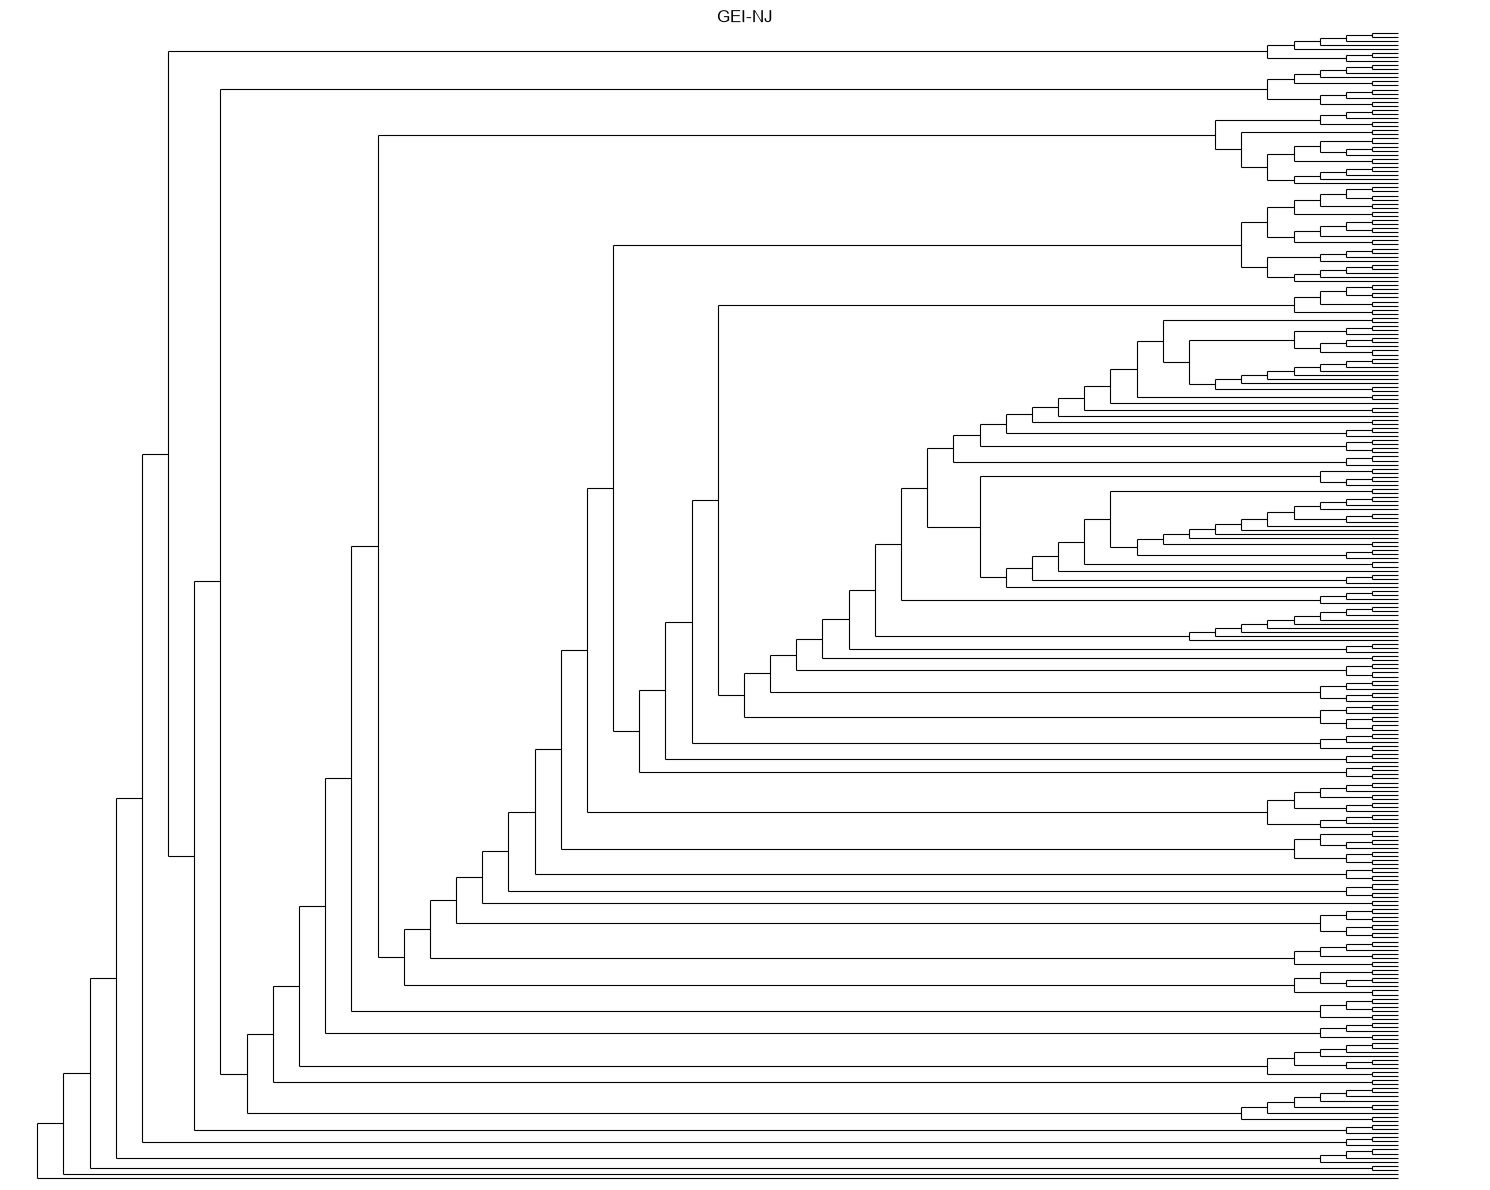

In [4]:
tree = build_nj(
    adata, do_plot=True, rapidnj_binary=RAPIDNJ_BINARY,
    layout="rectangular", figsize=(15, 12),
    savepath=OUTPUT_DIR / "00_GEI-NJ_branch_lengths_F.pdf",
)

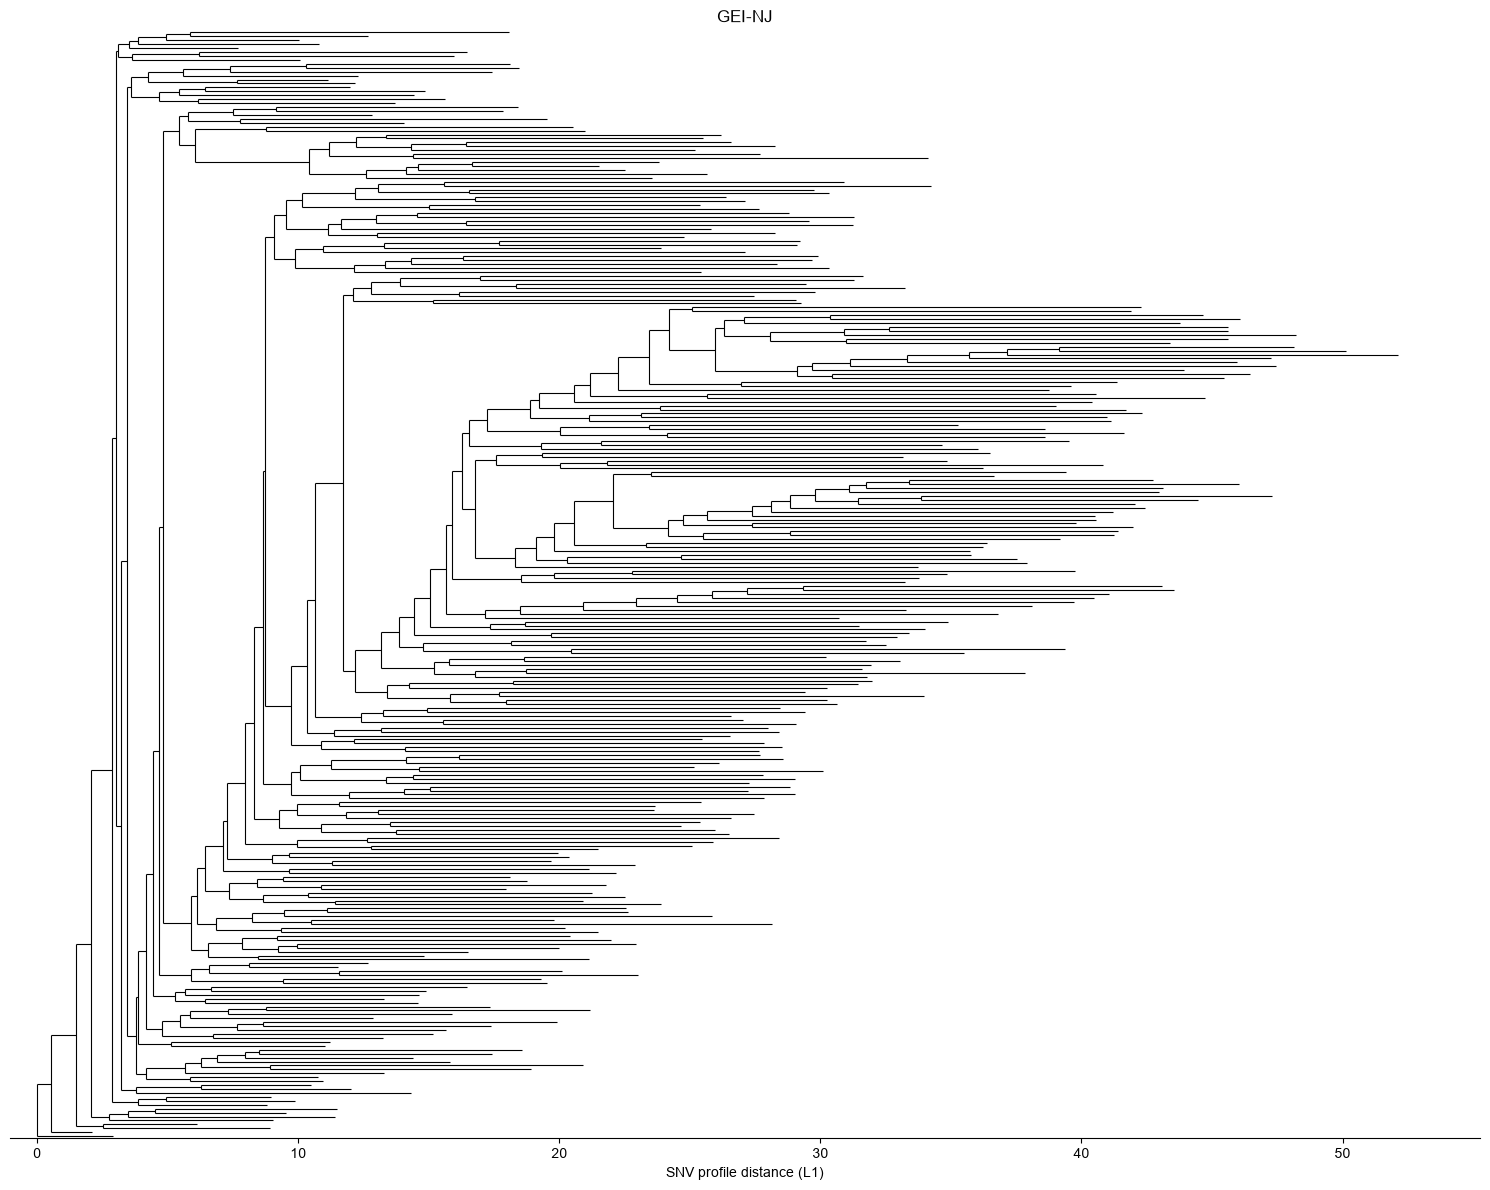

In [5]:
tree = build_nj(
    adata, do_plot=True, rapidnj_binary=RAPIDNJ_BINARY,
    use_branch_lengths=True,
    layout="rectangular", figsize=(15, 12),
    savepath=OUTPUT_DIR / "00_GEI-NJ_branch_lengths_T.pdf",
)

## Load cell type labels

Here, `data/cell_type.tsv` contains two tab-separated columns without a header: barcode and cell type. Labels are matched to bins by barcode.

In [6]:
mapping = pd.read_csv("data/cell_type.tsv", sep="\t", header=None,
                      names=["barcode", "cell_type"])
mapping = mapping.apply(lambda col: col.str.strip())
mapping.loc[mapping.cell_type.str.lower() == "mixed", "cell_type"] = "Mixed"
adata.obs["cell_type"] = mapping.set_index("barcode").loc[adata.obs_names, "cell_type"]

CELL_TYPE_COLORS = {
    "Early_nodule_cortex": "#A6D96A",
    "Infected_Zone": "#F8766D",
    "Meristems": "#336699",
    "Vascular_tissue": "#FDB863",
    "Mixed": "#9970AB",
}

adata.obs.head()

,cell_type
17700_20600,Infected_Zone
17700_20650,Meristems
17700_20700,Meristems
17700_20750,Meristems
17700_20800,Meristems


## Rectangular layout colored by cell type

The following three plots use topology views (`use_branch_lengths=False`) with aligned tips. This changes only the display, not the inferred topology or branch lengths.

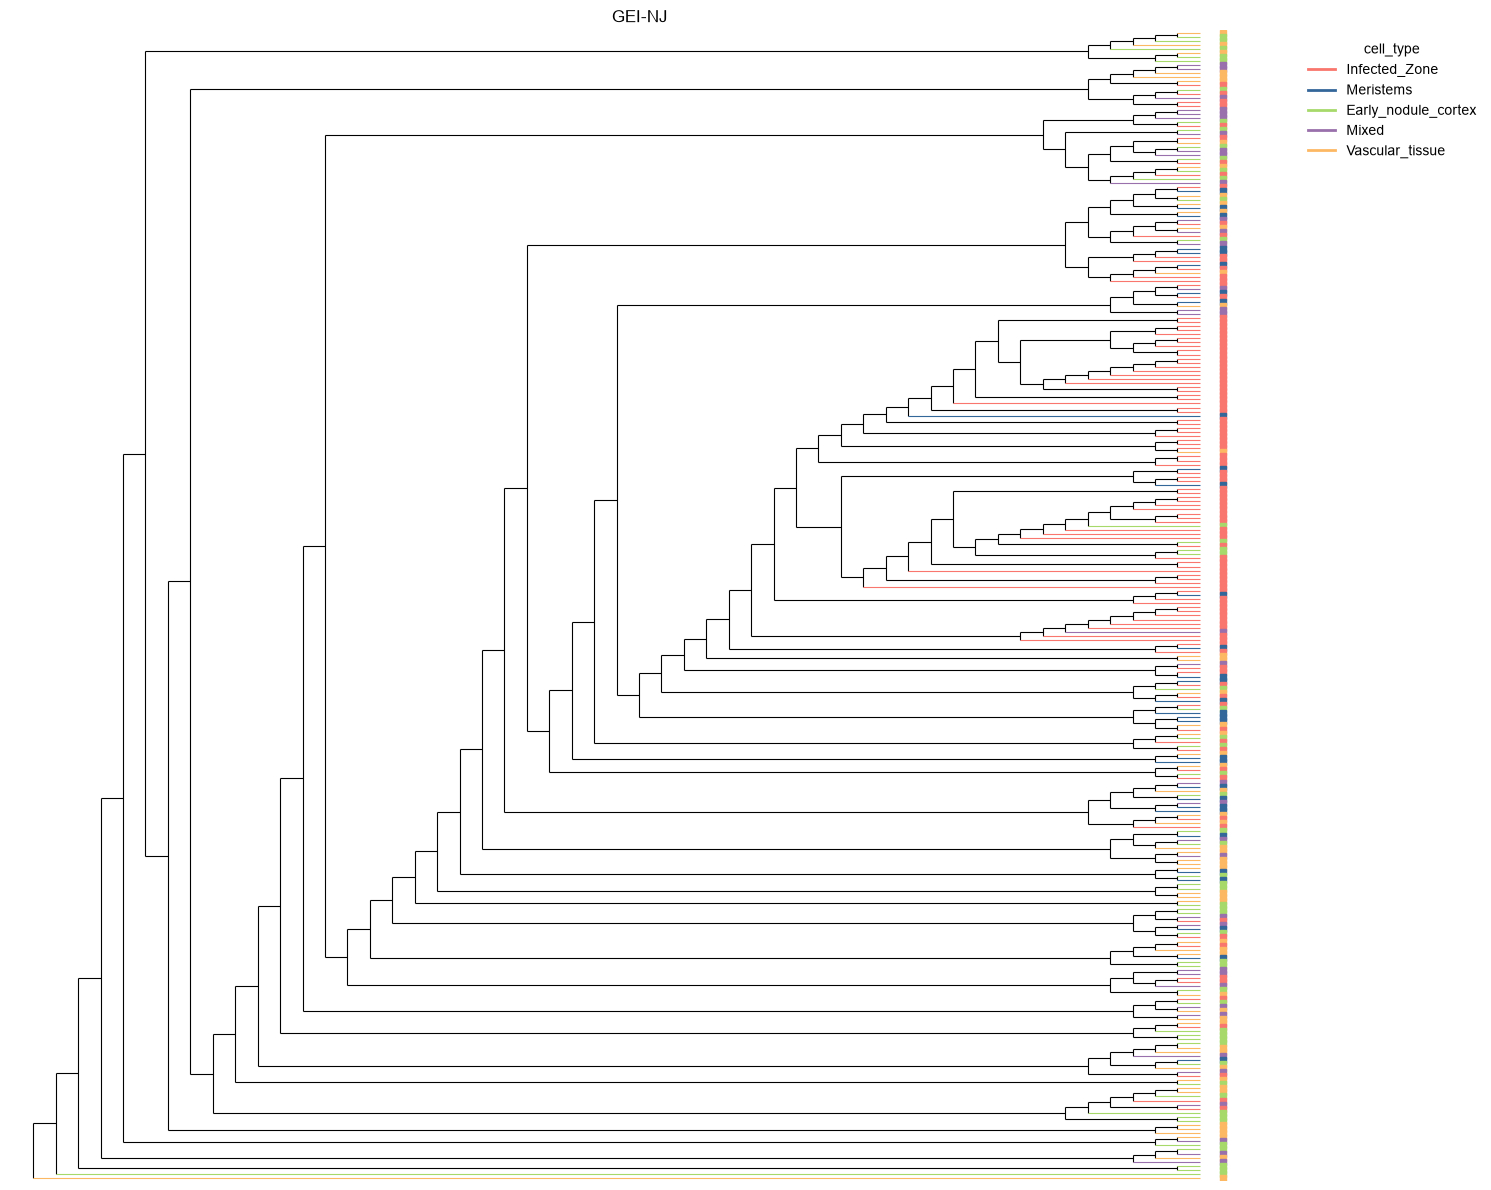

In [7]:
tree = build_nj(
    adata, do_plot=True, rapidnj_binary=RAPIDNJ_BINARY,
    group_key="cell_type", group_colors=CELL_TYPE_COLORS,
    leafcolor_onside=True, show_leaf_labels=False,
    use_branch_lengths=False,
    layout="rectangular", figsize=(15, 12),
    savepath=OUTPUT_DIR / "01_GEI-NJ_rectangular.pdf",
)

## Triangular layout colored by cell type

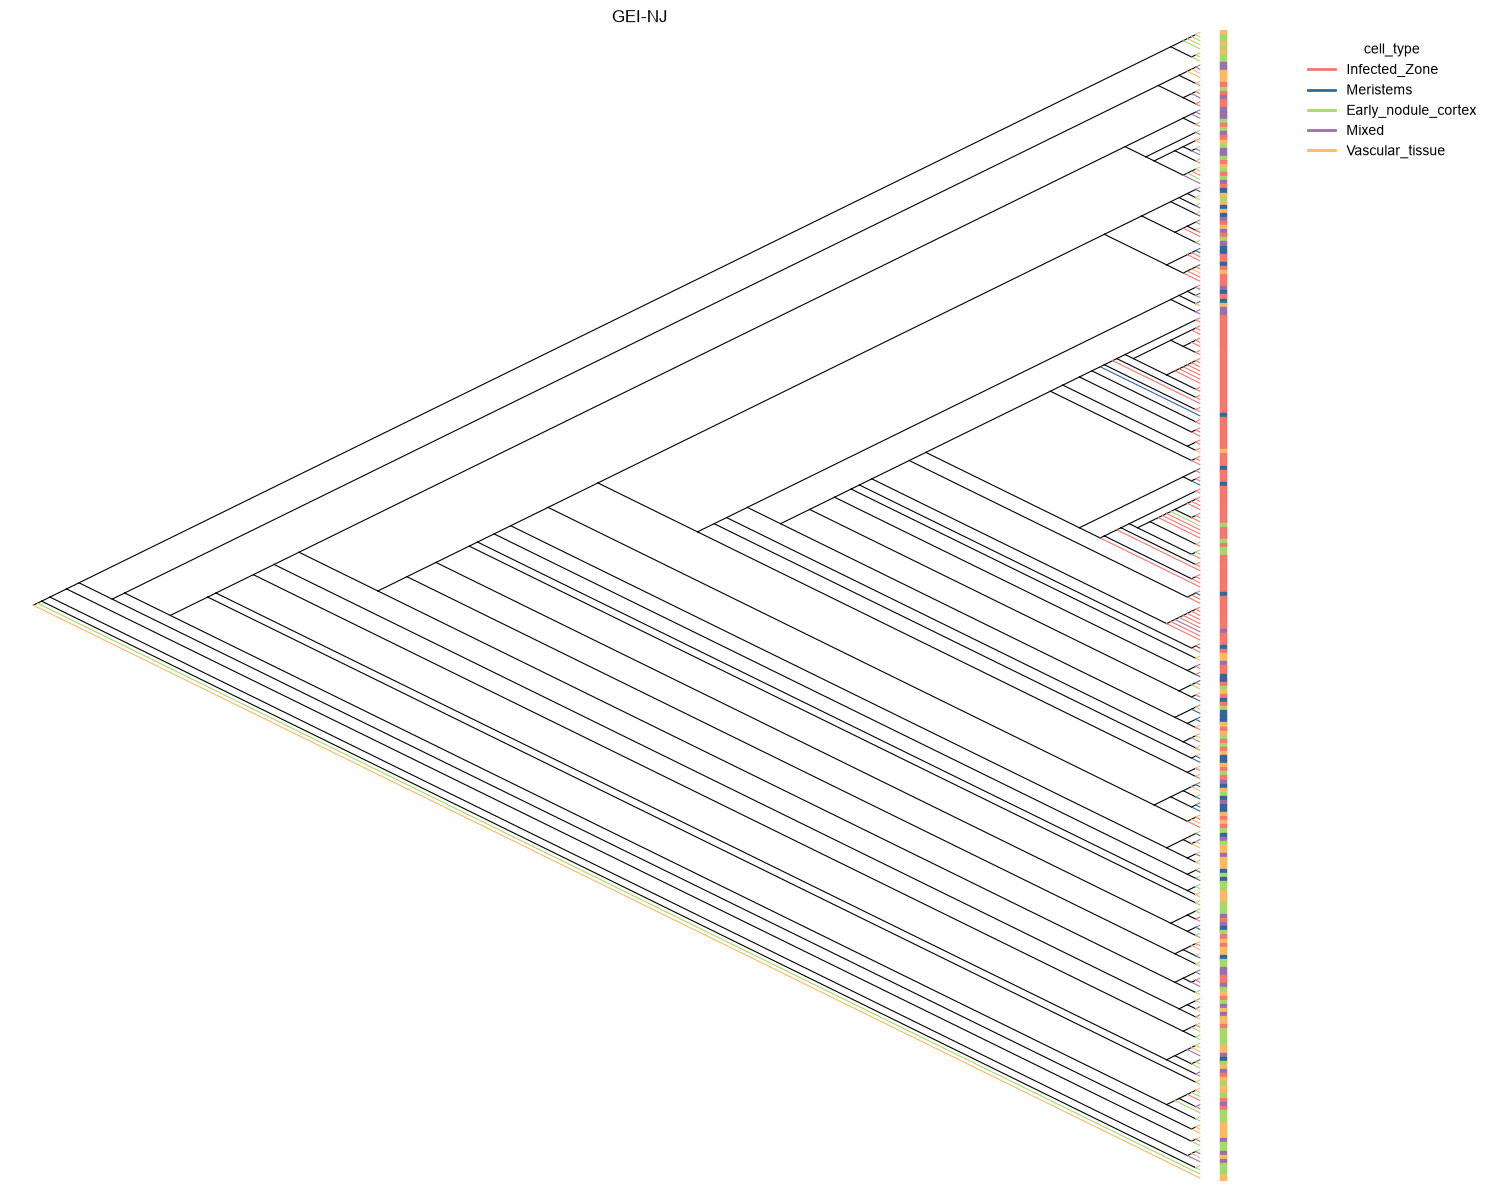

In [8]:
tree = build_nj(
    adata, do_plot=True, rapidnj_binary=RAPIDNJ_BINARY,
    group_key="cell_type", group_colors=CELL_TYPE_COLORS,
    leafcolor_onside=True, show_leaf_labels=False,
    use_branch_lengths=False,
    layout="triangular", figsize=(15, 12),
    savepath=OUTPUT_DIR / "02_GEI-NJ_triangular.pdf",
)

## Circular layout colored by cell type

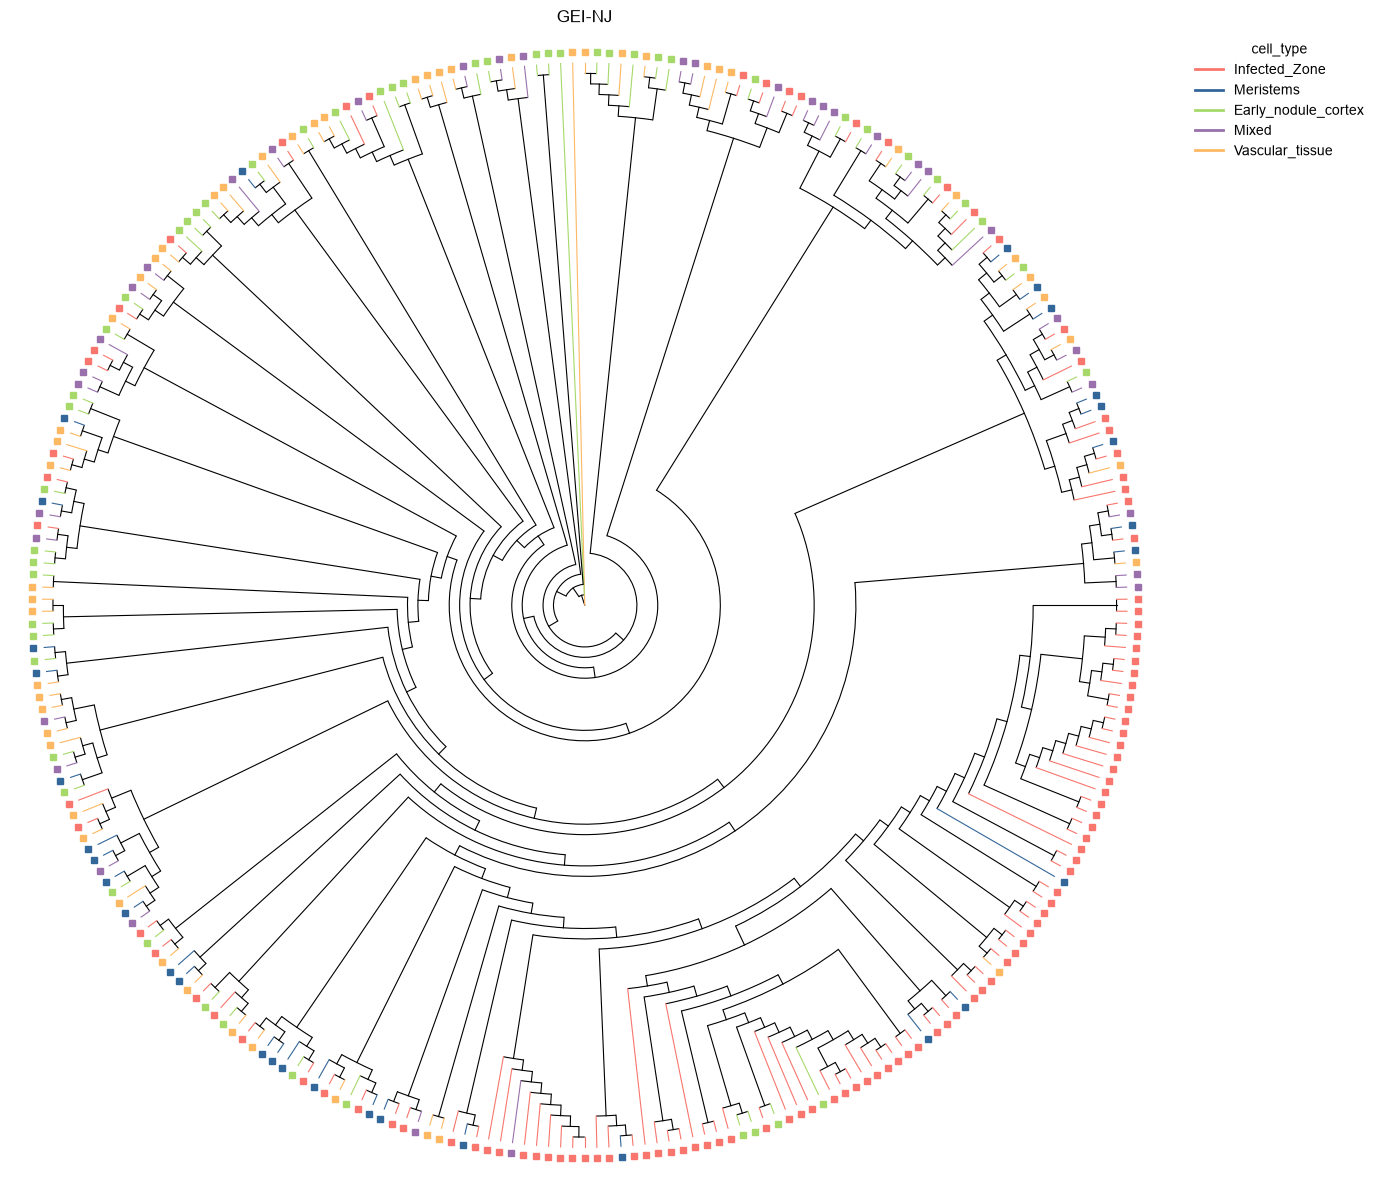

In [9]:
tree = build_nj(
    adata, do_plot=True, rapidnj_binary=RAPIDNJ_BINARY,
    group_key="cell_type", group_colors=CELL_TYPE_COLORS,
    leafcolor_onside=True, show_leaf_labels=False,
    use_branch_lengths=False,
    layout="circular", figsize=(15, 12),
    savepath=OUTPUT_DIR / "03_GEI-NJ_circular.pdf",
    newick_path=OUTPUT_DIR / "GEI-NJ_binary.nwk",
)

## Save the circular HTML viewer

Here, `data/cell_coordinates.tsv` contains three tab-separated columns without a header: barcode, x, and y. Coordinates are matched by barcode. The viewer inherits the circular layout and cell type colors from `tree`. Open the saved HTML file in a browser.

In [10]:
html_path = view_tree_coords(
    tree, coords_path="data/cell_coordinates.tsv",
    savepath=OUTPUT_DIR / "05_GEI-NJ_circular_tree_coords.html",
    x_label="Spatial X", y_label="Spatial Y",
)